# 05 - External validation on IDRiD

**Model:** `efficientnet_b0_v2_best.pth`, unchanged (best epoch 9, trained on APTOS only). **Data:** all 516 IDRiD images (413 training + 103 testing parts), none of which was used for training, epoch selection or threshold tuning. IDRiD is evaluated once; nothing is tuned on it.

## Decision rule, fixed BEFORE looking at the results

Primary operating point: referable DR (grade 2 or higher), using the summed probability of grades 2 to 4 at threshold 0.5. The 0.2 threshold (tuned on APTOS validation) is reported separately as a secondary result.

| Metric on IDRiD (point estimate) | Keep the model as is | Inconclusive | Retrain (background removed) |
|---|---|---|---|
| Referable AUC (APTOS validation: 0.976) | 0.95 or more | 0.90 to 0.95 | below 0.90 |
| Referable sensitivity at 0.5 (APTOS validation: 0.920) | 0.85 or more | 0.75 to 0.85 | below 0.75 |
| QWK (APTOS validation: 0.926) | 0.80 or more | 0.70 to 0.80 | below 0.70 |

**Overall decision:** KEEP if all three metrics are in the "keep" column; RETRAIN if at least one metric is in the "retrain" column; otherwise INCONCLUSIVE (then we look at the confusion matrix, the confidence intervals and Grad-CAM before deciding). Bootstrap 95% confidence intervals are reported to judge how close the call is.

**Caveats:** QWK and accuracy depend on the grade mix, which differs from APTOS. A poor result does not prove that the background is the cause: retraining would be an experiment (v3 versus v2 on the same IDRiD images). If we retrain after seeing this result, the decision was informed by IDRiD, and the README will say so.

## 1. Loading and checking the IDRiD labels
We check the prepared labels, the grade distribution, and that every processed image exists.

In [1]:
import sys
sys.path.append("..")

%load_ext autoreload
%autoreload 2

import numpy as np, pandas as pd, cv2
import torch, torch.nn as nn
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import cohen_kappa_score, roc_auc_score, confusion_matrix
from torch.utils.data import DataLoader

from src.model import create_model
from src.dataset import RetinaDataset, get_transforms, DATA
from src.engine import evaluate

BASE = DATA / "external" / "idrid"
labels = pd.read_csv(BASE / "labels.csv")
print(len(labels), "images")
print(pd.crosstab(labels.diagnosis, labels.split, margins=True))
referable = labels.diagnosis >= 2
print("Referable (grade 2+):", int(referable.sum()), f"({referable.mean():.1%}) | non-referable:", int((~referable).sum()))
missing = [c for c in labels.id_code if not (BASE / "processed_512" / f"{c}.png").exists()]
print("Missing processed files:", len(missing))

516 images
split      test  train  All
diagnosis                  
0            34    134  168
1             5     20   25
2            32    136  168
3            19     74   93
4            13     49   62
All         103    413  516
Referable (grade 2+): 323 (62.6%) | non-referable: 193
Missing processed files: 0


**Interpretation:** 516 images (413 training and 103 testing parts), none missing. The grade mix is 168 / 25 / 168 / 93 / 62 for grades 0 to 4, so 323 images (62.6%) are referable, against 39% in the APTOS validation set. Only 25 images are Mild, so the recall of that grade is very uncertain.

## 2. Visual check of the preprocessing, and brightness compared with APTOS
Raw images (top) versus the preprocessed versions (bottom), and the brightness distribution of the processed images compared with the APTOS validation set. A large difference would warn us of a domain shift before any metric is computed.

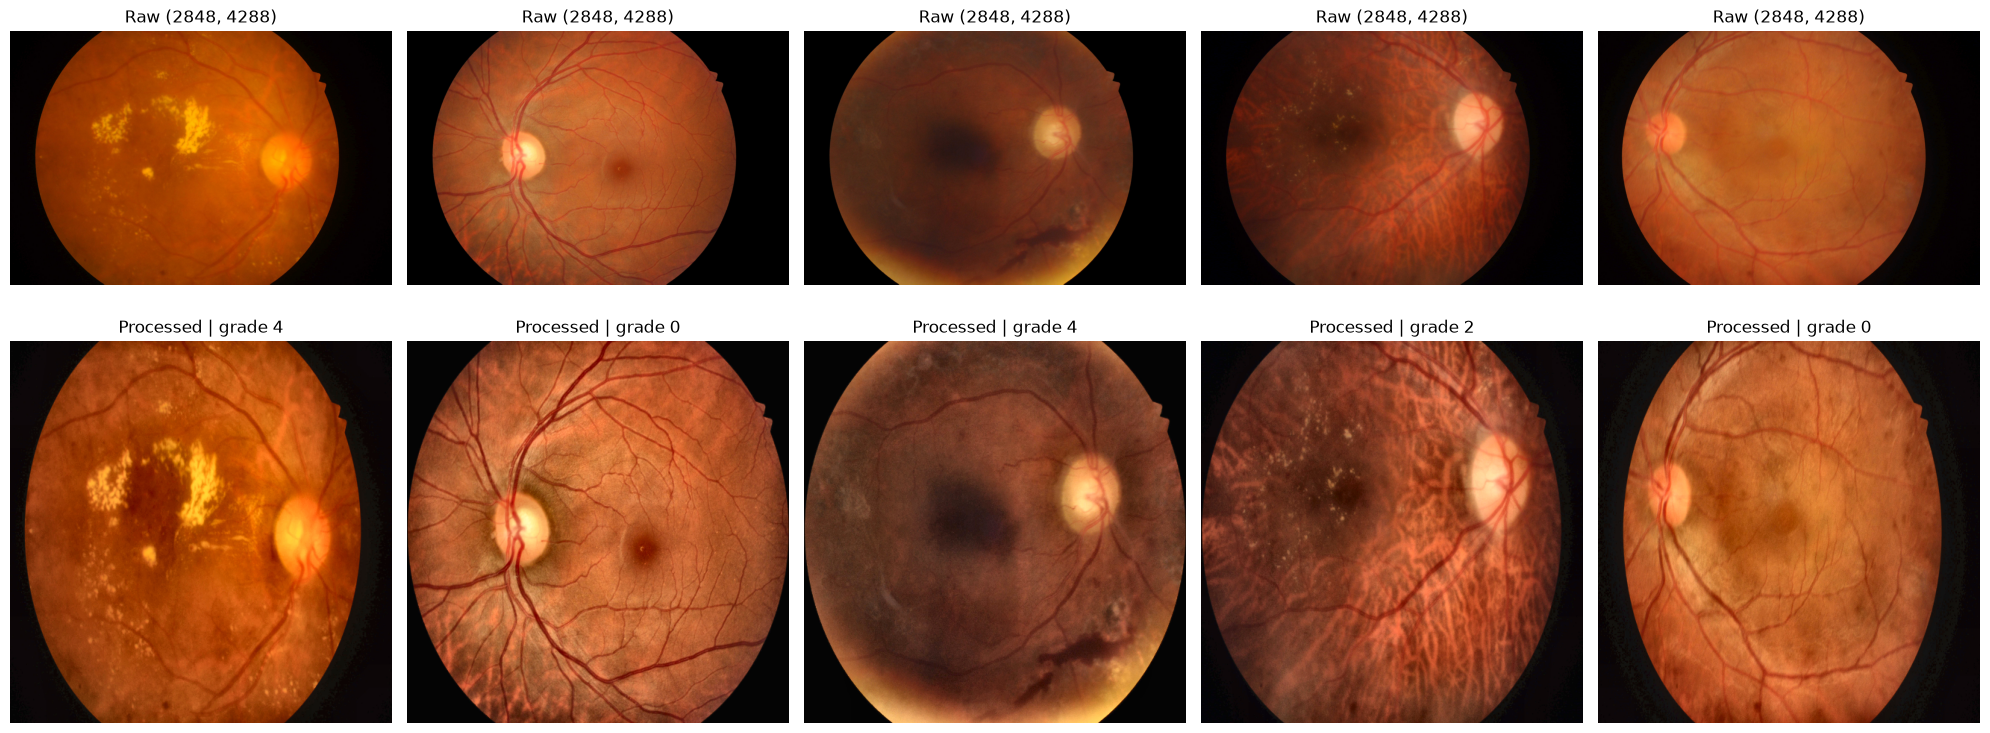

IDRiD      brightness: mean 78.5 | std 11.0 | min 43.2 | max 116.5
APTOS val  brightness: mean 75.2 | std 11.9 | min 33.3 | max 112.9


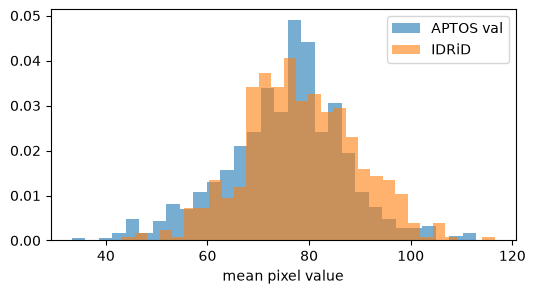

In [2]:
sample = labels.sample(5, random_state=3)
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for j, (_, r) in enumerate(sample.iterrows()):
    split_dir = "a. Training Set" if r.split == "train" else "b. Testing Set"
    raw_path = BASE / "raw" / "B. Disease Grading" / "1. Original Images" / split_dir / f"{r.orig_name}.jpg"
    raw = cv2.cvtColor(cv2.imread(str(raw_path)), cv2.COLOR_BGR2RGB)
    proc = cv2.cvtColor(cv2.imread(str(BASE / "processed_512" / f"{r.id_code}.png")), cv2.COLOR_BGR2RGB)
    axes[0, j].imshow(raw);  axes[0, j].set_title(f"Raw {raw.shape[:2]}"); axes[0, j].axis("off")
    axes[1, j].imshow(proc); axes[1, j].set_title(f"Processed | grade {r.diagnosis}"); axes[1, j].axis("off")
plt.tight_layout(); plt.show()

idrid_b = [cv2.imread(str(BASE / "processed_512" / f"{c}.png")).mean() for c in labels.id_code]
aptos_val = pd.read_csv(DATA / "splits" / "val.csv")
aptos_b = [cv2.imread(str(DATA / "processed_512" / f"{c}.png")).mean() for c in aptos_val.id_code]
for name, b in [("IDRiD", idrid_b), ("APTOS val", aptos_b)]:
    print(f"{name:10s} brightness: mean {np.mean(b):.1f} | std {np.std(b):.1f} | min {np.min(b):.1f} | max {np.max(b):.1f}")
plt.figure(figsize=(6, 3))
plt.hist(aptos_b, bins=30, alpha=0.6, density=True, label="APTOS val")
plt.hist(idrid_b, bins=30, alpha=0.6, density=True, label="IDRiD")
plt.xlabel("mean pixel value"); plt.legend(); plt.show()

**Interpretation:** mean brightness of the processed images is 78.5 on IDRiD (std 11.0, range 43.2 to 116.5) against 75.2 on the APTOS validation set (std 11.9, range 33.3 to 112.9), so there is no gross difference in exposure. [Add what the figure shows: crop, framing, colors.]

## 3. Predictions of the unchanged APTOS model on IDRiD
The saved weights are loaded and the 516 images are run through the model with the same transforms as the APTOS validation set (no augmentation). Nothing is tuned on these images.

In [3]:
device = torch.device("cuda")
model = create_model(pretrained=False).to(device)
model.load_state_dict(torch.load("../models/efficientnet_b0_v2_best.pth", map_location=device))
model.eval()

ds = RetinaDataset(BASE / "labels.csv", BASE / "processed_512", get_transforms(False))
loader = DataLoader(ds, batch_size=16, shuffle=False, num_workers=0)
m = evaluate(model, loader, nn.CrossEntropyLoss(), device)
probs, y = m["probs"], m["y_true"]
pred = probs.argmax(axis=1)
print("Images:", len(ds), "| order matches labels.csv:", bool((y == labels.diagnosis.values).all()))

Images: 516 | order matches labels.csv: True


**Interpretation:** 516 images were scored in the same order as `labels.csv`, so predictions and labels are aligned.

## 4. Metrics with bootstrap confidence intervals, and the verdict
Point estimates and 95% bootstrap intervals (2,000 resamples of the 516 images), compared with the APTOS validation values, then the pre-specified decision rule applied mechanically.

In [4]:
rng = np.random.default_rng(42)
p_ref = probs[:, 2:].sum(axis=1)       # summed probability of grades 2 to 4
is_ref = y >= 2

def metrics(idx):
    yt, pr, pp, ir = y[idx], pred[idx], p_ref[idx], is_ref[idx]
    flag = pp >= 0.5
    return {
        "QWK": cohen_kappa_score(yt, pr, weights="quadratic"),
        "referable AUC": roc_auc_score(ir, pp),
        "referable sensitivity (0.5)": (flag & ir).sum() / ir.sum(),
        "referable specificity (0.5)": (~flag & ~ir).sum() / (~ir).sum(),
        "accuracy": (yt == pr).mean(),
    }

point = metrics(np.arange(len(y)))
boot = pd.DataFrame([metrics(rng.integers(0, len(y), len(y))) for _ in range(2000)])
ci = boot.quantile([0.025, 0.975]).T

res = pd.DataFrame({"IDRiD": pd.Series(point),
                    "CI low": ci[0.025], "CI high": ci[0.975],
                    "APTOS val": pd.Series({"QWK": 0.926, "referable AUC": 0.976,
                                            "referable sensitivity (0.5)": 0.920,
                                            "referable specificity (0.5)": 0.965,
                                            "accuracy": 0.862})}).round(3)
display(res)
print("Macro AUC (5 grades, one-vs-rest): IDRiD", round(m["auc_macro"], 3), "| APTOS val 0.925")

RULE = {   # metric: (keep if >=, retrain if <)  -- must equal the table in the first cell
    "referable AUC": (0.95, 0.90),
    "referable sensitivity (0.5)": (0.85, 0.75),
    "QWK": (0.80, 0.70),
}
verdicts = {k: ("KEEP" if point[k] >= keep else "RETRAIN" if point[k] < retrain else "INCONCLUSIVE")
            for k, (keep, retrain) in RULE.items()}
display(pd.Series(verdicts, name="verdict"))
overall = ("KEEP" if all(v == "KEEP" for v in verdicts.values())
           else "RETRAIN" if any(v == "RETRAIN" for v in verdicts.values())
           else "INCONCLUSIVE")
print("OVERALL DECISION:", overall)

,IDRiD,CI low,CI high,APTOS val
QWK,0.650,0.590,0.702,0.926
referable AUC,0.910,0.883,0.934,0.976
referable sensitivity (0.5),0.678,0.628,0.730,0.920
referable specificity (0.5),0.969,0.941,0.990,0.965
accuracy,0.405,0.362,0.450,0.862


Macro AUC (5 grades, one-vs-rest): IDRiD 0.791 | APTOS val 0.925


referable AUC                  INCONCLUSIVE
referable sensitivity (0.5)         RETRAIN
QWK                                 RETRAIN
Name: verdict, dtype: str

OVERALL DECISION: RETRAIN


**Interpretation (APTOS model on IDRiD, n = 516)**

| Metric | IDRiD (95% CI) | APTOS validation | Verdict |
|---|---|---|---|
| QWK | 0.650 (0.590 to 0.702) | 0.926 | RETRAIN |
| Referable AUC | 0.910 (0.883 to 0.934) | 0.976 | INCONCLUSIVE |
| Referable sensitivity at 0.5 | 0.678 (0.628 to 0.730) | 0.920 | RETRAIN |
| Referable specificity at 0.5 | 0.969 (0.941 to 0.990) | 0.965 | not in the rule |
| Accuracy | 0.405 (0.362 to 0.450) | 0.862 | |
| Macro AUC | 0.791 | 0.925 | |

- Overall decision under the rule fixed in advance: **RETRAIN** (two of three metrics in the retrain column). The sensitivity interval lies entirely below the 0.75 cutoff, so this verdict is not borderline; the upper end of the QWK interval (0.702) touches its cutoff.
- Specificity is unchanged, so non-referable images are still recognized. The loss is on the other side: 104 of 323 referable patients are missed at threshold 0.5.
- The ranking of patients is partly preserved (referable AUC 0.910), but the scores are shifted: many referable IDRiD patients receive too little referable probability.
- The grade mix differs (62.6% referable in IDRiD against 39% in APTOS validation), which affects accuracy and QWK and may explain part of the lower sensitivity at a fixed threshold, but not all of the drop.
- This is a zero-shot test of an APTOS-trained model on a single clinic and camera, with images selected as gradable and of good quality. It shows that performance dropped, not why.

## 5. Confusion matrix and recall per grade

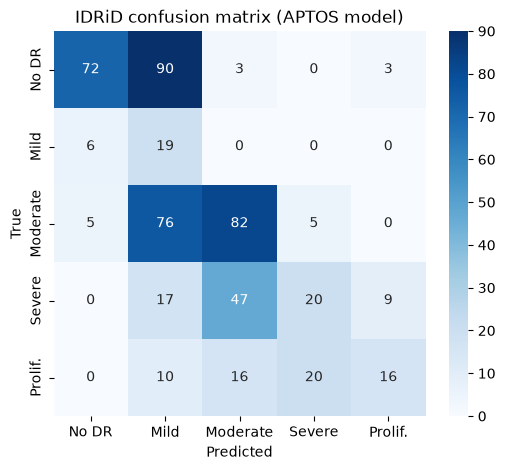

          n images  recall
No DR          168   0.429
Mild            25   0.760
Moderate       168   0.488
Severe          93   0.215
Prolif.         62   0.258


In [5]:
names = ["No DR", "Mild", "Moderate", "Severe", "Prolif."]
cm = confusion_matrix(y, pred, labels=list(range(5)))
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=names, yticklabels=names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("IDRiD confusion matrix (APTOS model)")
plt.show()
print(pd.DataFrame({"n images": cm.sum(1), "recall": (cm.diagonal() / cm.sum(1)).round(3)}, index=names))

**Interpretation:** recall per grade on IDRiD is 0.429 (No DR, n = 168), 0.760 (Mild, 25), 0.488 (Moderate, 168), 0.215 (Severe, 93) and 0.258 (Proliferative, 62), against 0.972, 0.765, 0.816, 0.486 and 0.648 on the APTOS validation set. Accuracy is 0.405. Because referable specificity stays at 0.969, healthy images that are not recognized as No DR must mostly be predicted as Mild, and the low recall of the severe grades shows that advanced disease is under-graded. [Confirm with the matrix: which off-diagonal cells are largest?] Only 25 images are Mild, so that recall is very uncertain.

## 6. Referral threshold (secondary result)
The 0.2 threshold was chosen on the APTOS validation set. Here it is a hypothesis being tested, not tuned.

In [6]:
print("threshold | sensitivity | specificity | missed | false alarms")
for t in [0.5, 0.4, 0.3, 0.2, 0.1]:
    flag = p_ref >= t
    tp = (flag & is_ref).sum(); fn = (~flag & is_ref).sum()
    tn = (~flag & ~is_ref).sum(); fp = (flag & ~is_ref).sum()
    print(f"   {t:.2f}   |    {tp/(tp+fn):.3f}    |    {tn/(tn+fp):.3f}    |  {fn:3d}   |  {fp:3d}")

threshold | sensitivity | specificity | missed | false alarms
   0.50   |    0.678    |    0.969    |  104   |    6
   0.40   |    0.724    |    0.948    |   89   |   10
   0.30   |    0.752    |    0.927    |   80   |   14
   0.20   |    0.820    |    0.902    |   58   |   19
   0.10   |    0.889    |    0.788    |   36   |   41


**Interpretation:** lowering the threshold raises sensitivity on IDRiD (0.678 at 0.5, 0.752 at 0.3, 0.820 at 0.2, 0.889 at 0.1) at the cost of specificity (0.969, 0.927, 0.902, 0.788). Even at 0.2, the APTOS choice, sensitivity (0.820, 58 missed) stays well below the APTOS value (0.971) and below the 0.85 cutoff of the decision rule, so the threshold chosen on APTOS does not transfer. A threshold chosen on IDRiD would be tuned on the external data, so it is not used for the decision.

## 7. Diagnosis: memorization or dataset shift?
The same model is evaluated on APTOS training images (no augmentation), APTOS validation images and IDRiD. We also compare the distribution of predicted grades and the share of black background.

In [7]:
from scipy.stats import spearmanr
from src.dataset import get_dataloaders

_, aptos_loader, _, aptos_ds = get_dataloaders(batch_size=16, num_workers=0)
ma = evaluate(model, aptos_loader, nn.CrossEntropyLoss(), device)

def summary(name, probs_, y_):
    pred_ = probs_.argmax(1)
    exp_ = probs_ @ np.arange(5)
    print(f"{name}: predicted counts {np.bincount(pred_, minlength=5)} | true counts {np.bincount(y_, minlength=5)}")
    print(f"   mean expected grade for true grades 0..4: {[round(float(exp_[y_ == g].mean()), 2) for g in range(5)]}")
    print(f"   Spearman(expected grade, true grade): {spearmanr(exp_, y_).statistic:.3f}")

summary("IDRiD", probs, y)
summary("APTOS val", ma["probs"], ma["y_true"])

def black_share(codes, folder):
    return np.mean([(cv2.imread(str(folder / f"{c}.png"), cv2.IMREAD_GRAYSCALE) <= 20).mean() for c in codes])
print("Black-area share: IDRiD", round(black_share(labels.id_code, BASE / "processed_512"), 3),
      "| APTOS val", round(black_share(aptos_ds.df.id_code, DATA / "processed_512"), 3))

IDRiD: predicted counts [ 83 212 148  45  28] | true counts [168  25 168  93  62]
   mean expected grade for true grades 0..4: [0.77, 0.85, 1.59, 2.19, 2.51]
   Spearman(expected grade, true grade): 0.789
APTOS val: predicted counts [351  89 187  31  43] | true counts [359  68 185  35  54]
   mean expected grade for true grades 0..4: [0.23, 1.3, 1.99, 2.56, 3.09]
   Spearman(expected grade, true grade): 0.898
Black-area share: IDRiD 0.195 | APTOS val 0.162


In [8]:
tr_ds = RetinaDataset(DATA / "splits" / "train.csv", DATA / "processed_512", get_transforms(False))
tr_loader = DataLoader(tr_ds, batch_size=16, shuffle=False, num_workers=0)
mt = evaluate(model, tr_loader, nn.CrossEntropyLoss(), device)

_, aptos_loader, _, _ = get_dataloaders(batch_size=16, num_workers=0)
ma = evaluate(model, aptos_loader, nn.CrossEntropyLoss(), device)

def row(name, mm):
    p, yy = mm["probs"], mm["y_true"]
    flag, ir = p[:, 2:].sum(1) >= 0.5, yy >= 2
    return {"set": name, "n": len(yy), "QWK": mm["qwk"], "accuracy": mm["acc"],
            "referable AUC": mm["auc_referable"], "referable sensitivity (0.5)": (flag & ir).sum() / ir.sum()}

display(pd.DataFrame([row("APTOS train", mt), row("APTOS validation", ma), row("IDRiD", m)]).set_index("set").round(3))

,n,QWK,accuracy,referable AUC,referable sensitivity (0.5)
set,,,,,
APTOS train,2803,0.993,0.983,1.000,0.988
APTOS validation,701,0.926,0.862,0.976,0.920
IDRiD,516,0.650,0.405,0.910,0.678


**Interpretation**

| | APTOS train | APTOS validation | IDRiD |
|---|---|---|---|
| QWK | 0.993 | 0.926 | 0.650 |
| Accuracy | 0.983 | 0.862 | 0.405 |
| Referable AUC | 1.000 | 0.976 | 0.910 |
| Referable sensitivity (0.5) | 0.988 | 0.920 | 0.678 |

- **Some memorization:** accuracy falls from 0.983 on training images to 0.862 on validation (QWK -0.067). The gap between validation and IDRiD is three to four times larger (QWK -0.276, accuracy -0.457, sensitivity -0.242), so the main problem is dataset shift, not overfitting alone.
- **Predicted grades on IDRiD** are 83 / 212 / 148 / 45 / 28 for grades 0 to 4, against true counts of 168 / 25 / 168 / 93 / 62. Mild is predicted 212 times for 25 true Mild images (the Mild recall of 0.76 corresponds to about 19 correct predictions out of 212), while Severe and Proliferative are strongly under-predicted. On APTOS validation the predicted counts follow the true counts closely.
- **The scores are compressed:** the mean expected grade of true No DR images is 0.77 on IDRiD against 0.23 on APTOS, and it is lower by 0.37 to 0.58 for every disease grade. The order of the grades is mostly preserved (Spearman 0.789 against 0.898), except that No DR and Mild are almost indistinguishable (0.77 and 0.85). This explains why referable AUC stays at 0.91 while sensitivity at threshold 0.5 drops.
- **Exposure and framing are not the explanation:** mean brightness is similar (78.5 and 75.2) and the black-area share is 0.195 on IDRiD against 0.162 on APTOS.
- The cause is not identified. Candidates, none tested: camera and color differences, lesion size at 512 px (all IDRiD images are 4288x2848), differences in grading conventions between the two sets of graders, and APTOS-specific cues.